# 실전 — 실제 데이터로 검증: UNSW-NB15 로 검증하기 (현대 flow 데이터)

NSL-KDD 브리지가 1990년대 계열 데이터였다면, 이 노트북은 **현대 flow 기반 데이터셋 UNSW-NB15**(ch08 의 5개 데이터셋 중 하나)에 ch09 전처리 + ch14 지도학습 파이프라인을 그대로 얹는다. proto·service·state 범주형을 One-Hot 으로 처리하는 실제 사례이자, 9개 공격 범주(정상 포함 10개 클래스)(Worms·Analysis 등 극희소 포함)에서 클래스 불균형이 얼마나 심각한지 실측한다.

> **인터넷 필요**: 실행 시 UNSW-NB15 train/test CSV(약 47MB)를 HuggingFace 미러에서 내려받는다.

핵심 관찰: (1) 현대 flow 데이터에서도 이진 탐지는 AUC ~0.98 로 강하다. (2) 그러나 **Analysis·Backdoor·Worms·Fuzzers 같은 희소·모호 공격은 `class_weight='balanced'` 를 써도 recall 이 0.1~0.15 수준**으로 거의 못 잡는다 — ch14·ch16 의 '정확도가 아니라 클래스별 recall·macro-F1' 교훈이 실데이터에서 그대로 드러난다.

## 데이터셋 이야기 — 어떻게 수집됐나 (UNSW-NB15)

**2015년 호주 UNSW Canberra 사이버센터(ACCS)** 가 만들었다. IXIA PerfectStorm 장비로 **실제 정상 트래픽과 최신 합성 공격을 동시에 생성**해 100GB 규모의 pcap 을 캡처한 뒤, Argus·Bro(Zeek) 로 49개 flow feature 를 추출했다. Fuzzers·Backdoor·Worms 등 **9개 현대 공격 범주(정상 포함 10개 클래스)**를 담아 낡은 NSL-KDD 의 공격 분포를 대체하려는 목적이었다.

**시나리오**: 현대적 공격 믹스에서 flow 통계만으로 공격 유형까지 분류할 수 있는가.

In [ ]:
# 파트별 노트북은 같은 종류의 공통 데이터·모델 작업 폴더를 사용합니다.
from pathlib import Path as _BookPath
import os as _book_os
_book_cwd = _BookPath.cwd()
if (_book_cwd.name in {"part1", "part2", "part3", "part4"}
        and _book_cwd.parent.name in {"instructor", "exercises", "solutions"}):
    _book_os.chdir(_book_cwd.parent)


In [1]:
# !pip install pandas scikit-learn matplotlib

from pathlib import Path
import matplotlib
from matplotlib import font_manager
for fp in ['/usr/share/fonts/truetype/nanum/NanumGothic.ttf',
           '/usr/share/fonts/truetype/nanum/NanumBarunGothic.ttf']:
    if Path(fp).exists():
        font_manager.fontManager.addfont(fp)
        matplotlib.rcParams['font.family'] = font_manager.FontProperties(fname=fp).get_name()
        break
matplotlib.rcParams['axes.unicode_minus'] = False

import urllib.request, ssl, os
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.ensemble import RandomForestClassifier
from sklearn.pipeline import Pipeline
from sklearn.metrics import classification_report, confusion_matrix, roc_auc_score

## 1. 실데이터 내려받기

UNSW-NB15 는 IXIA 트래픽 생성기로 만든 현대 공격 데이터셋으로, 49개 flow feature 와 9개 공격 범주(정상 포함 10개 클래스)를 담는다. 공개 미러에서 공식 train/test 파티션을 받는다.

In [2]:
BASE = 'https://huggingface.co/datasets/Mireu-Lab/UNSW-NB15/resolve/main/'
def fetch(fname):
    if not os.path.exists(fname):
        req = urllib.request.Request(BASE + fname, headers={'User-Agent': 'Mozilla/5.0'})
        with urllib.request.urlopen(req, timeout=120, context=ssl.create_default_context()) as r:
            open(fname, 'wb').write(r.read())
    return fname

train = pd.read_csv(fetch('train.csv'))
test  = pd.read_csv(fetch('test.csv'))
print('train:', train.shape, ' test:', test.shape)
print('\n공격 범주(train):')
print(train['attack_cat'].value_counts())

train: (82332, 45)  test: (175341, 45)

공격 범주(train):
attack_cat
Normal            37000
Generic           18871
Exploits          11132
Fuzzers            6062
DoS                4089
Reconnaissance     3496
Analysis            677
Backdoor            583
Shellcode           378
Worms                44
Name: count, dtype: int64


## 2. 전처리 파이프라인 (ch09 과 동일)

`proto`·`service`·`state` 3개 범주형은 One-Hot, 나머지 수치형은 표준화한다. NSL-KDD 와 feature 는 다르지만 **ColumnTransformer 골격은 완전히 동일**하다 — 이것이 파이프라인 재사용의 힘이다.

In [3]:
CAT = ['proto', 'service', 'state']
DROP = ['id', 'label', 'attack_cat']
NUM = [c for c in train.columns if c not in CAT + DROP]
for c in CAT:
    train[c] = train[c].astype(str)
    test[c] = test[c].astype(str)

pre = ColumnTransformer([
    ('num', StandardScaler(), NUM),
    ('cat', OneHotEncoder(handle_unknown='ignore'), CAT),
])
print(f'수치형 {len(NUM)}개, 범주형 {len(CAT)}개(proto·service·state)')

수치형 39개, 범주형 3개(proto·service·state)


## 3. 이진 탐지 (normal vs attack)

In [4]:
clf = Pipeline([
    ('pre', pre),
    ('rf', RandomForestClassifier(n_estimators=120, random_state=42, n_jobs=-1)),
]).fit(train, train['label'])

proba = clf.predict_proba(test)[:, 1]
pred = (proba > 0.5).astype(int)
print(classification_report(test['label'], pred, target_names=['normal', 'attack'], digits=3))
print('ROC-AUC:', round(roc_auc_score(test['label'], proba), 3))

              precision    recall  f1-score   support

      normal      0.780     0.976     0.867     56000
      attack      0.987     0.871     0.925    119341

    accuracy                          0.904    175341
   macro avg      0.883     0.923     0.896    175341
weighted avg      0.921     0.904     0.907    175341

ROC-AUC: 0.983


## 4. 9개 공격 범주(정상 포함 10개 클래스) 분류 — 희소 클래스의 벽

`class_weight='balanced'` 를 써도 표본이 적거나 정상과 겹치는 범주(Analysis·Backdoor·Worms·Fuzzers)는 recall 이 바닥이다. **정확도 하나로는 이 실패가 안 보인다** — 클래스별 recall 을 반드시 봐야 한다.

In [5]:
clf10 = Pipeline([
    ('pre', pre),
    ('rf', RandomForestClassifier(n_estimators=120, random_state=42, n_jobs=-1,
                                  class_weight='balanced')),
]).fit(train, train['attack_cat'])

pred10 = clf10.predict(test)
print(classification_report(test['attack_cat'], pred10, digits=3))

                precision    recall  f1-score   support

      Analysis      0.050     0.017     0.025      2000
      Backdoor      0.072     0.128     0.092      1746
           DoS      0.339     0.634     0.442     12264
      Exploits      0.826     0.538     0.652     33393
       Fuzzers      0.742     0.123     0.210     18184
       Generic      0.942     0.982     0.962     40000
        Normal      0.752     0.986     0.853     56000
Reconnaissance      0.930     0.711     0.806     10491
     Shellcode      0.681     0.445     0.538      1133
         Worms      0.826     0.146     0.248       130

      accuracy                          0.745    175341
     macro avg      0.616     0.471     0.483    175341
  weighted avg      0.775     0.745     0.722    175341



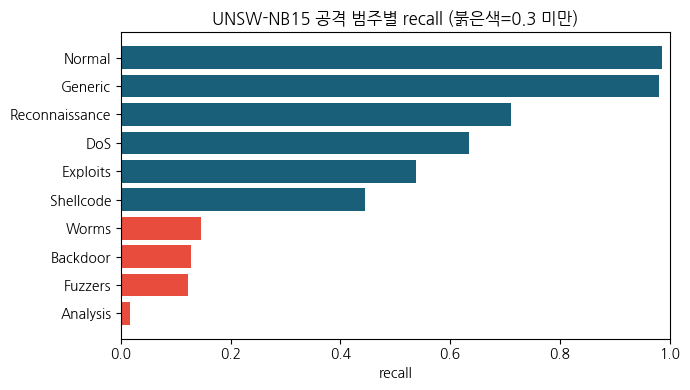

In [6]:
# 범주별 recall 막대그래프 — 희소 클래스가 얼마나 안 잡히는지
from sklearn.metrics import recall_score
cats = sorted(test['attack_cat'].unique())
rec = [recall_score(test['attack_cat'] == c, pred10 == c) for c in cats]
order = np.argsort(rec)
fig, ax = plt.subplots(figsize=(7, 4))
ax.barh([cats[i] for i in order], [rec[i] for i in order],
        color=['#e74c3c' if rec[i] < 0.3 else '#1a5f7a' for i in order])
ax.set_xlabel('recall'); ax.set_title('UNSW-NB15 공격 범주별 recall (붉은색=0.3 미만)')
ax.set_xlim(0, 1); plt.tight_layout(); plt.show()

## 5. 정리

| 관찰 | NSL-KDD 브리지 | UNSW-NB15(현대 flow) |
|---|---|---|
| 이진 ROC-AUC | ~0.96 | ~0.98 |
| 잘 잡는 범주 | DoS·Probe | Generic·Reconnaissance |
| **거의 못 잡는 범주** | R2L·U2R | **Analysis·Backdoor·Worms·Fuzzers** |

1. **같은 ColumnTransformer 골격이 데이터만 바꿔 그대로 동작한다** — feature 도, 범주형 컬럼도 다르지만 파이프라인은 동일하다.
2. **현대 데이터셋에서도 희소·모호 공격은 여전히 벽이다.** `class_weight='balanced'` 로도 recall 0.1 대에 머무는 범주가 여럿이다 — 데이터 보강·이상 탐지 결합(ch11)·클래스별 임계값(ch16) 이 필요한 이유다.
3. **정확도(0.90)만 보면 이 실패가 숨는다.** 반드시 클래스별 recall·macro-F1 로 평가해야 한다(ch14·ch16).

> 더 나아가려면: 희소 범주에 SMOTE·오버샘플링(ch08)을 적용하거나, 이진 탐지 후 공격만 2차로 세분류하는 계층 구조를 실험해 보라.